# Day 3: Detector error analysis and shelf-gap detection

Run on the Azure ML compute instance (**Python 3.10 - AzureML** kernel).

- **Part A** finds *which* products the detector misses: by size, position on the image, and how crowded the shelf is.
- **Part B** groups detections into shelf rows and flags empty gaps, then checks each gap against the labels.

Needs `src/boxes.py` and `src/gaps.py` in the repo, the test images in `~/datasets/SKU-110K`,
and the trained model in `~/runs/full/weights/best.pt`.

**Done when:** gaps are drawn on sample shelves and look sensible.

## Setup

In [1]:
import glob, os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from PIL import Image, ImageOps

# Find the repo's src folder whether this notebook sits in notebooks/, src/ or the repo root
SRC = next(os.path.abspath(p) for p in ["../src", "src", "."] if os.path.exists(os.path.join(p, "gaps.py")))
sys.path.insert(0, SRC)
from boxes import load_yolo_labels, match_boxes, occupancy_mask, rect_coverage
from gaps import detect_gaps

SKU = os.path.expanduser("~/datasets/SKU-110K")
WEIGHTS = os.path.expanduser("~/runs/full/weights/best.pt")
IMGSZ = 640        # the size the model was trained at
CONF = 0.25        # confidence threshold for counting a detection
N_IMAGES = 300     # random test images to analyse (about 3-5 minutes on CPU)
OUT = os.path.expanduser("~/runs/day3")
os.makedirs(OUT, exist_ok=True)

BLUE, ORANGE, VIOLET, INK = "#2a78d6", "#eb6834", "#6250d6", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "figure.dpi": 110,
})

test_imgs = sorted(glob.glob(f"{SKU}/images/test_*.jpg"))
rng = np.random.default_rng(42)
sample = sorted(rng.choice(test_imgs, size=min(N_IMAGES, len(test_imgs)), replace=False))
import psutil
mem = psutil.virtual_memory()
print(f"src: {SRC}\n{len(test_imgs)} test images, analysing {len(sample)}")
print(f"Memory: {mem.available / 1e9:.1f} GB free of {mem.total / 1e9:.1f} GB")
if mem.available < 6e9:
    print("WARNING: under 6 GB free. Shut down other notebook kernels before continuing.")


def label_path(name):
    return f"{SKU}/labels/{os.path.splitext(name)[0]}.txt"


def show_image(ax, name):
    img = ImageOps.exif_transpose(Image.open(f"{SKU}/images/{name}"))
    ax.imshow(img); ax.axis("off"); ax.grid(False)

src: /mnt/batch/tasks/shared/LS_root/mounts/clusters/ci-hairfann/code/Users/22643787/retail-shelf-intelligence/src
2936 test images, analysing 300
Memory: 13.2 GB free of 14.7 GB


# Part A: What does the detector miss?

## A1. Run the model on the sample
Runs one image at a time and saves the result. If the kernel restarts, this cell reloads the saved predictions instead of running the model again.

In [2]:
# PREDICT
import gc
import psutil

PRED_FILE, SIZE_FILE = f"{OUT}/preds_test_sample.parquet", f"{OUT}/image_sizes.parquet"
if os.path.exists(PRED_FILE) and os.path.exists(SIZE_FILE):
    pred_df, size_df = pd.read_parquet(PRED_FILE), pd.read_parquet(SIZE_FILE)
    print(f"Loaded saved predictions: {len(pred_df):,} detections on {len(size_df)} images "
          f"(delete {PRED_FILE} to re-run the model)")
else:
    from ultralytics import YOLO

    model = YOLO(WEIGHTS)
    rows, sizes = [], []
    t0 = time.time()
    # One path at a time: given a list, Ultralytics loads every image into memory up front
    # (~24 MB each at full resolution), which is what crashed the kernel.
    for i, path in enumerate(sample, 1):
        r = model.predict(str(path), imgsz=IMGSZ, conf=CONF, max_det=1000, verbose=False)[0]
        name = os.path.basename(r.path)
        h, w = r.orig_shape
        sizes.append((name, w, h))
        xyxy, conf = r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()
        rows.append(pd.DataFrame({"image": name, "x1": xyxy[:, 0], "y1": xyxy[:, 1],
                                  "x2": xyxy[:, 2], "y2": xyxy[:, 3], "conf": conf}))
        del r
        if i % 25 == 0 or i == len(sample):
            gc.collect()
            print(f"{i}/{len(sample)} images, {time.time() - t0:.0f}s, "
                  f"RAM in use {psutil.virtual_memory().percent:.0f}%")

    pred_df = pd.concat(rows, ignore_index=True)
    size_df = pd.DataFrame(sizes, columns=["image", "w", "h"])
    pred_df.to_parquet(PRED_FILE, index=False)
    size_df.to_parquet(SIZE_FILE, index=False)
    del model
    gc.collect()
    print(f"{len(pred_df):,} detections on {len(size_df)} images in {time.time() - t0:.0f}s")

/anaconda/envs/azureml_py38/lib/python3.10/site-packages/torch/cuda/__init__.py:611: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
[transformers] Disabling PyTorch because PyTorch >= 2.5 is required but found 2.1.2+cu121
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


25/300 images, 27s, RAM in use 14%
50/300 images, 33s, RAM in use 13%
75/300 images, 40s, RAM in use 14%
100/300 images, 48s, RAM in use 14%
125/300 images, 56s, RAM in use 15%
150/300 images, 63s, RAM in use 13%
175/300 images, 70s, RAM in use 15%
200/300 images, 78s, RAM in use 14%
225/300 images, 86s, RAM in use 15%
250/300 images, 95s, RAM in use 14%
275/300 images, 103s, RAM in use 12%
300/300 images, 112s, RAM in use 14%
47,476 detections on 300 images in 113s


## A2. Match detections to the labels
A detection counts as correct if it overlaps a labelled product by IoU ≥ 0.5.
For every labelled product we record whether it was found, its size **as the model sees it**
(pixels after the photo is shrunk to 640), where it sits vertically, and whether it touches the image edge.

In [3]:
preds_by_img = {k: g for k, g in pred_df.groupby("image")}
NO_BOXES = pd.DataFrame(columns=["x1", "y1", "x2", "y2", "conf"])


def pred_boxes(name):
    p = preds_by_img.get(name, NO_BOXES)
    return p[["x1", "y1", "x2", "y2"]].to_numpy(float), p["conf"].to_numpy(float)


gt_rows, img_rows = [], []
for name, w, h in size_df.itertuples(index=False):
    gt = load_yolo_labels(label_path(name), w, h)
    pb, pc = pred_boxes(name)
    tp, gt_hit = match_boxes(pb, pc, gt, iou_thr=0.5)
    scale = IMGSZ / max(w, h)
    for (x1, y1, x2, y2), hit in zip(gt, gt_hit):
        gt_rows.append((name, hit, np.sqrt((x2 - x1) * (y2 - y1)) * scale, (y1 + y2) / 2 / h,
                        x1 < 0.01 * w or y1 < 0.01 * h or x2 > 0.99 * w or y2 > 0.99 * h))
    img_rows.append((name, len(gt), len(pb), int(tp.sum()), int((~tp).sum()), int((~gt_hit).sum())))

gt_df = pd.DataFrame(gt_rows, columns=["image", "found", "size_px", "y_pos", "edge"])
img_df = pd.DataFrame(img_rows, columns=["image", "n_gt", "n_pred", "tp", "fp", "fn"])
img_df["recall"] = img_df.tp / img_df.n_gt.clip(lower=1)
img_df["precision"] = img_df.tp / img_df.n_pred.clip(lower=1)
gt_df = gt_df.merge(img_df[["image", "n_gt"]], on="image")

P, R = img_df.tp.sum() / img_df.n_pred.sum(), img_df.tp.sum() / img_df.n_gt.sum()
print(f"At conf {CONF} and IoU 0.5 on {len(img_df)} test images: precision {P:.3f}, recall {R:.3f}")
print(f"Missed products: {img_df.fn.sum():,} of {img_df.n_gt.sum():,} | extra boxes: {img_df.fp.sum():,}")
print(f"Typical product size seen by the model: {gt_df.size_px.median():.0f} px")

At conf 0.25 and IoU 0.5 on 300 test images: precision 0.853, recall 0.900
Missed products: 4,474 of 44,950 | extra boxes: 7,000
Typical product size seen by the model: 26 px


## A3. Recall by product size, position, edge and crowding
Each panel shows the share of labelled products the model found. Bars are labelled with the number of products in each group.

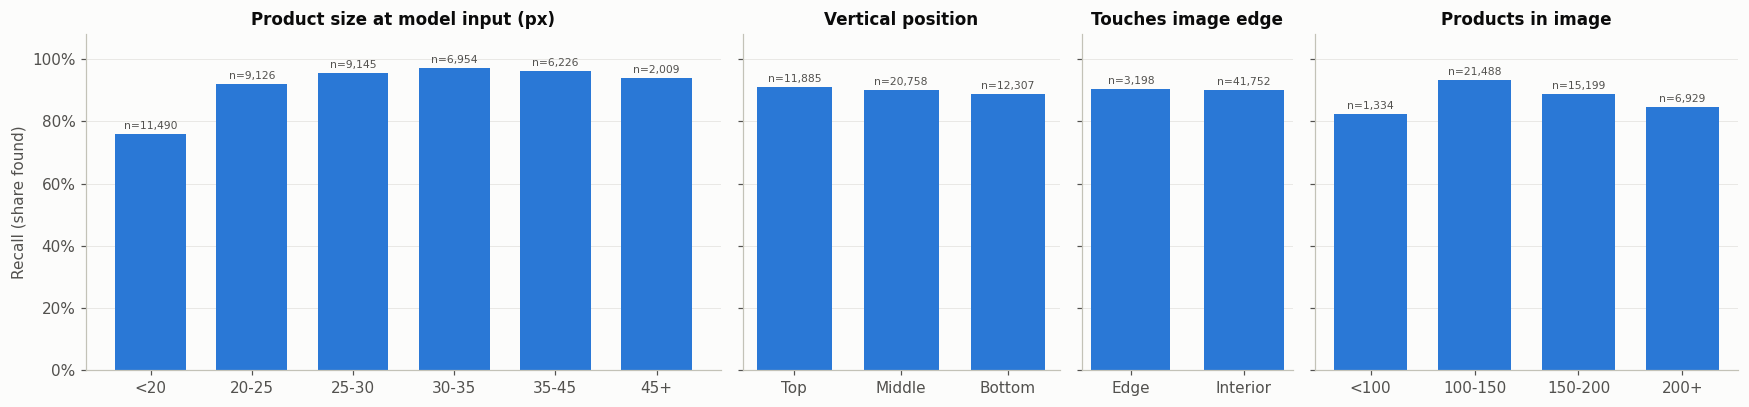

,recall,products,facet
<20,0.759,11490,Product size at model input (px)
20-25,0.920,9126,Product size at model input (px)
25-30,0.955,9145,Product size at model input (px)
30-35,0.971,6954,Product size at model input (px)
35-45,0.962,6226,Product size at model input (px)
45+,0.939,2009,Product size at model input (px)
Top,0.910,11885,Vertical position
Middle,0.902,20758,Vertical position
Bottom,0.888,12307,Vertical position
Edge,0.905,3198,Touches image edge


In [4]:
gt_df["Product size at model input (px)"] = pd.cut(
    gt_df.size_px, [0, 20, 25, 30, 35, 45, np.inf], labels=["<20", "20-25", "25-30", "30-35", "35-45", "45+"])
gt_df["Vertical position"] = pd.cut(gt_df.y_pos, [-0.01, 1 / 3, 2 / 3, 1.01], labels=["Top", "Middle", "Bottom"])
gt_df["Touches image edge"] = gt_df.edge.map({True: "Edge", False: "Interior"})
gt_df["Products in image"] = pd.cut(gt_df.n_gt, [0, 100, 150, 200, np.inf],
                                    labels=["<100", "100-150", "150-200", "200+"])
facets = ["Product size at model input (px)", "Vertical position", "Touches image edge", "Products in image"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True,
                         gridspec_kw={"width_ratios": [6, 3, 2, 4]})
summary = []
for ax, col in zip(axes, facets):
    grp = gt_df.groupby(col, observed=False)["found"].agg(["mean", "size"])
    bars = ax.bar(grp.index.astype(str), grp["mean"], width=0.7, color=BLUE)
    ax.bar_label(bars, labels=[f"n={n:,}" for n in grp["size"]], fontsize=7, color=INK, padding=2)
    ax.set(title=col, ylim=(0, 1.08))
    ax.grid(axis="x", visible=False)
    summary.append(grp.rename(columns={"mean": "recall", "size": "products"}).assign(facet=col))
axes[0].set_ylabel("Recall (share found)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(f"{OUT}/recall_breakdown.png", bbox_inches="tight"); plt.show()

summary_df = pd.concat(summary)
summary_df["recall"] = summary_df["recall"].round(3)
summary_df

### Reading the chart
- **Size:** if recall drops clearly for the smallest groups, products are too small at 640 px.
  That's the case for training at a larger size (the optional Kaggle run, `kaggle_finetune_1024.ipynb`).
- **Edge:** low recall at the edge means products cut off by the photo frame are often missed.
  That matters less for gaps, because gaps at the ends of rows are ignored anyway.
- **Crowding:** if very full shelves have lower recall, missed products there could look like gaps.

## A4. Look at the worst images
Blue = found, **orange = missed product**, **violet = detection with no matching label**.
Violet boxes are often real products that the labellers skipped, so check them before counting them as errors.

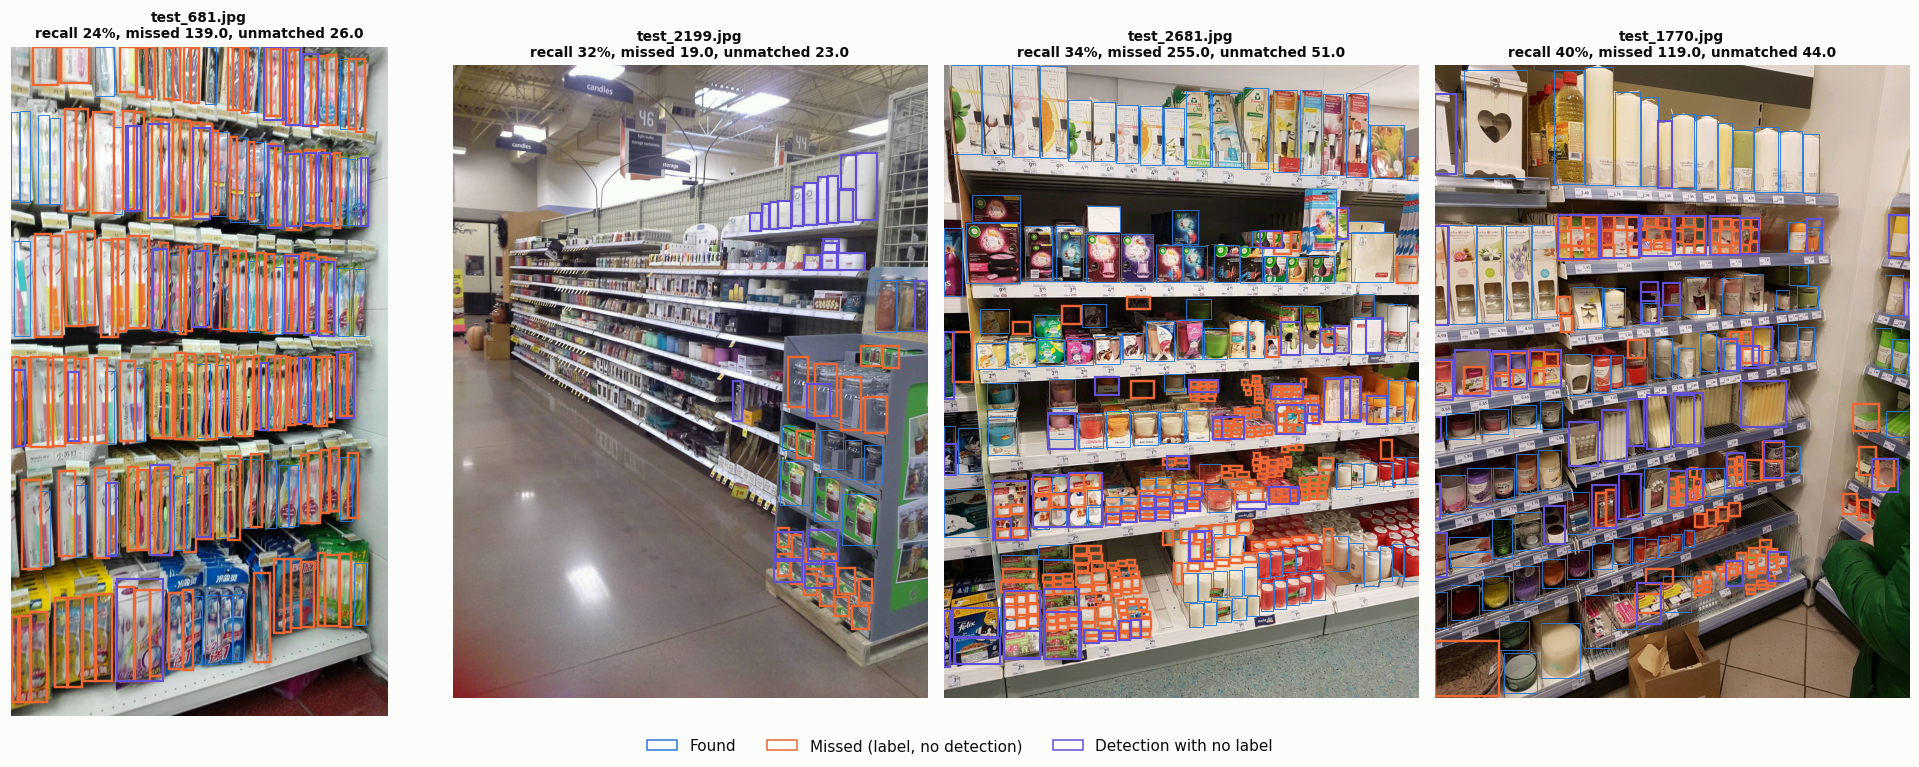

In [5]:
def draw_errors(ax, name):
    w, h = size_df.set_index("image").loc[name, ["w", "h"]]
    gt = load_yolo_labels(label_path(name), w, h)
    pb, pc = pred_boxes(name)
    tp, gt_hit = match_boxes(pb, pc, gt)
    show_image(ax, name)
    for boxes, color, lw in [(pb[tp], BLUE, 0.6), (gt[~gt_hit], ORANGE, 1.6), (pb[~tp], VIOLET, 1.4)]:
        for x1, y1, x2, y2 in boxes:
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=lw))
    row = img_df.set_index("image").loc[name]
    ax.set_title(f"{name}\nrecall {row.recall:.0%}, missed {row.fn}, unmatched {row.fp}", fontsize=9)


worst = img_df.sort_values("recall").head(4)["image"]
fig, axes = plt.subplots(1, 4, figsize=(18, 7))
for ax, name in zip(axes, worst):
    draw_errors(ax, name)
fig.legend(handles=[Patch(edgecolor=c, fill=False, label=l) for c, l in
                    [(BLUE, "Found"), (ORANGE, "Missed (label, no detection)"),
                     (VIOLET, "Detection with no label")]],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(f"{OUT}/worst_images.png", bbox_inches="tight"); plt.show()

img_df.to_parquet(f"{OUT}/per_image_errors.parquet", index=False)
gt_df.to_parquet(f"{OUT}/per_product_errors.parquet", index=False)

## A5. Failure types (write these in your own words)
1. **Small products:** …
2. **Image edges / cut-off products:** …
3. **Crowded or stacked shelves:** …
4. **Label quality (violet boxes that are real products):** …

# Part B: Shelf rows and gaps

For each image, detections are grouped into shelf rows (by their bottom edges), rows of items stacked on
other products are skipped, and any empty space between neighbours wider than one typical product is a gap.
Spaces at the ends of rows are ignored because a shelf can simply end there.

**Checking against the labels:** if the labels have products inside a detected gap, the "gap" was really
a product the detector missed. If the labels are empty there too, it's a real gap (or one the labellers also missed).

## B1. Detect gaps on every sampled image

In [6]:
def gaps_for(name, gap_factor=1.0):
    w, h = size_df.set_index("image").loc[name, ["w", "h"]]
    pb, _ = pred_boxes(name)
    gt = load_yolo_labels(label_path(name), w, h)
    res = detect_gaps(pb, w, h, gap_factor=gap_factor)
    gaps = res["gaps"].copy()
    gt_mask = occupancy_mask(gt, w, h)
    gaps["label_cover"] = [rect_coverage(gt_mask, r) for r in gaps[["x1", "y1", "x2", "y2"]].to_numpy()]
    gaps["missed_product"] = gaps["label_cover"] > 0.5
    return res, gaps, detect_gaps(gt, w, h, gap_factor=gap_factor)


gap_parts, score_rows = [], []
for name in size_df["image"]:
    res, gaps, gt_res = gaps_for(name)
    gap_parts.append(gaps.assign(image=name))
    rows = res["rows"]
    score_rows.append((name, res["score"], len(gaps), int(gaps["missed_product"].sum()),
                       len(set(rows[rows >= 0])), len(res["stacked_rows"]),
                       gt_res["score"], len(gt_res["gaps"])))

gaps_df = pd.concat(gap_parts, ignore_index=True)
score_df = pd.DataFrame(score_rows, columns=["image", "gap_score", "n_gaps", "n_missed_product_gaps",
                                             "n_rows", "n_stacked_rows", "label_gap_score", "label_n_gaps"])

n = len(score_df)
print(f"Shelf rows per image: median {score_df.n_rows.median():.0f} "
      f"({score_df.n_stacked_rows.sum()} stacked rows skipped in total)")
print(f"Gaps found from detections: {len(gaps_df)} in {(score_df.n_gaps > 0).sum()} of {n} images")
print(f"Gaps found from the labels themselves: {score_df.label_n_gaps.sum()} "
      f"in {(score_df.label_n_gaps > 0).sum()} of {n} images")
if len(gaps_df):
    share = gaps_df["missed_product"].mean()
    print(f"Detected gaps where the labels show a product (detector miss): {share:.0%}")
    print(f"Detected gaps that are empty in the labels too: {1 - share:.0%}")

Shelf rows per image: median 11 (690 stacked rows skipped in total)
Gaps found from detections: 1219 in 267 of 300 images
Gaps found from the labels themselves: 1142 in 252 of 300 images
Detected gaps where the labels show a product (detector miss): 16%
Detected gaps that are empty in the labels too: 84%


## B2. How strict should the gap rule be?
A gap must be wider than `gap_factor` × the row's typical product width. Wider thresholds find fewer gaps,
but a larger share of them are real. Pick the value that balances the two; Day 4's hand-labelled check will confirm it.

In [7]:
sens = []
for f in [0.75, 1.0, 1.5, 2.0]:
    g = pd.concat([gaps_for(name, f)[1] for name in size_df["image"]], ignore_index=True)
    sens.append((f, len(g), int((~g["missed_product"]).sum()) if len(g) else 0,
                 (~g["missed_product"]).mean() if len(g) else np.nan))
sens_df = pd.DataFrame(sens, columns=["gap_factor", "gaps_found", "empty_in_labels_too", "share_real"])
sens_df["share_real"] = sens_df["share_real"].map(lambda v: f"{v:.0%}" if pd.notna(v) else "-")
sens_df

,gap_factor,gaps_found,empty_in_labels_too,share_real
0,0.75,1598,1333,83%
1,1.00,1219,1019,84%
2,1.50,727,604,83%
3,2.00,452,369,82%


## B3. Draw gaps on sample shelves
Blue = detected products, dashed grey = detected shelf rows,
**orange = gap that's empty in the labels too**, **violet = "gap" where the labels show a product** (a detector miss).

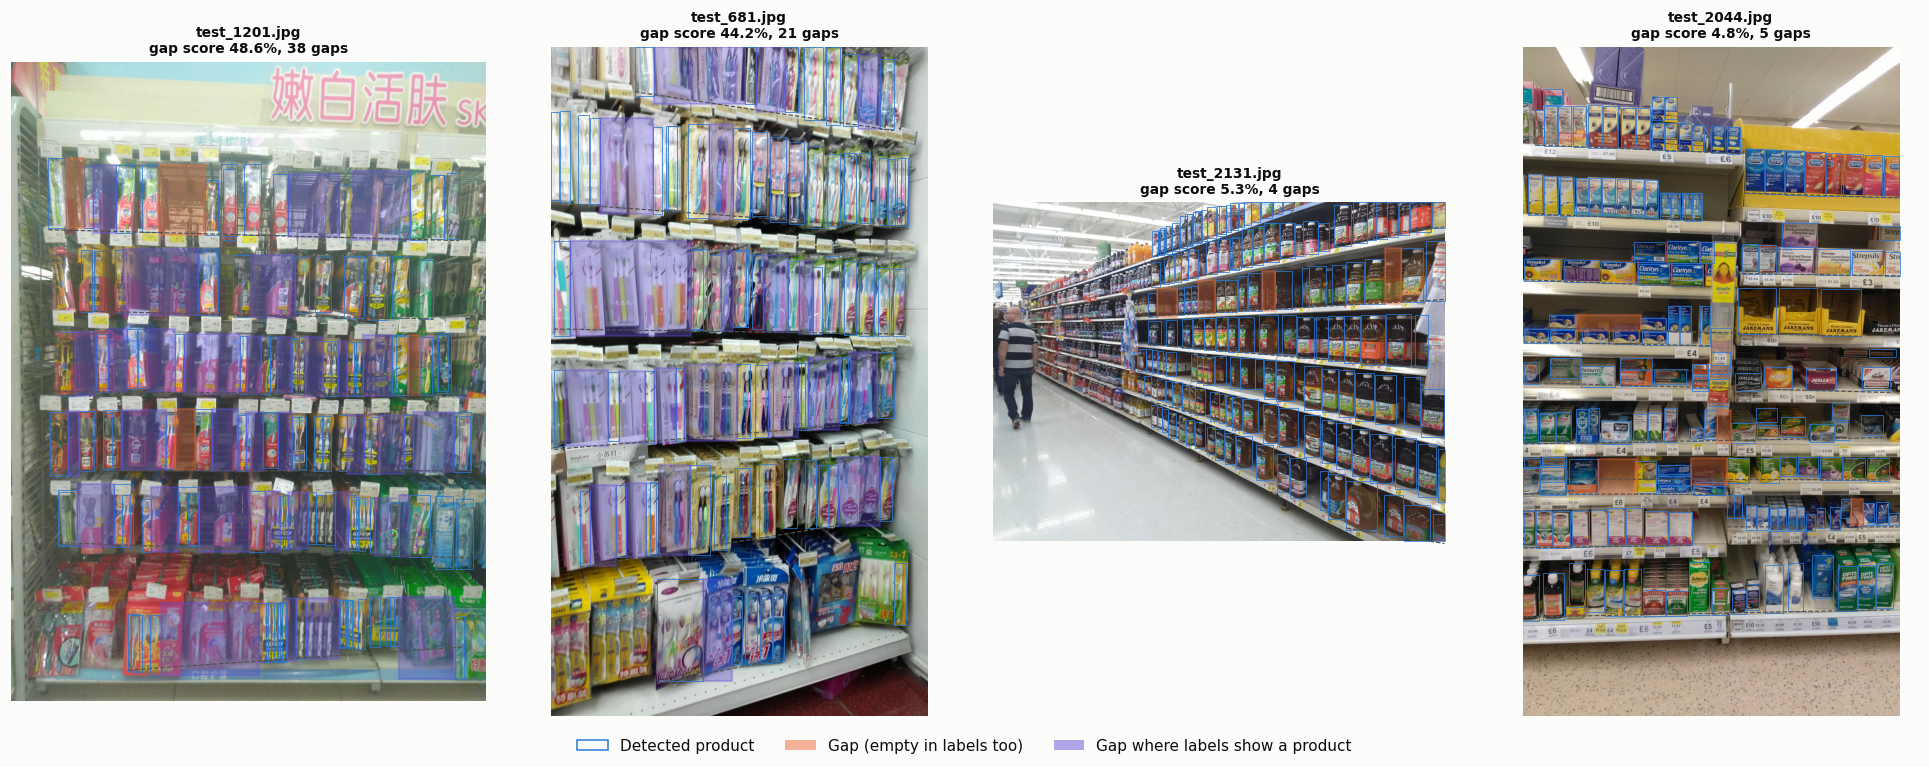

In [8]:
def draw_gaps(ax, name):
    w, h = size_df.set_index("image").loc[name, ["w", "h"]]
    pb, _ = pred_boxes(name)
    res, gaps, _ = gaps_for(name)
    show_image(ax, name)
    for x1, y1, x2, y2 in pb:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=BLUE, linewidth=0.5))
    rows = res["rows"]
    for r in np.unique(rows[rows >= 0]):
        rb = pb[rows == r]
        if len(rb) < 3 or r in res["stacked_rows"]:
            continue
        xc = (rb[:, 0] + rb[:, 2]) / 2
        s, c = np.polyfit(xc, rb[:, 3], 1)
        xs = np.array([rb[:, 0].min(), rb[:, 2].max()])
        ax.plot(xs, s * xs + c, color=INK, linestyle="--", linewidth=0.8)
    for g in gaps.itertuples():
        color = VIOLET if g.missed_product else ORANGE
        ax.add_patch(Rectangle((g.x1, g.y1), g.x2 - g.x1, g.y2 - g.y1, facecolor=color, alpha=0.35,
                               edgecolor=color, linewidth=1.5))
    ax.set_title(f"{name}\ngap score {res['score']:.1%}, {len(gaps)} gaps", fontsize=9)


with_gaps = score_df[score_df.n_gaps > 0]
picks = list(with_gaps.nlargest(2, "gap_score")["image"])
picks += list(with_gaps[~with_gaps.image.isin(picks)].sample(min(2, max(len(with_gaps) - 2, 0)),
                                                             random_state=0)["image"])
picks += list(score_df[~score_df.image.isin(picks)].sample(4 - len(picks), random_state=1)["image"])

fig, axes = plt.subplots(1, 4, figsize=(18, 7))
for ax, name in zip(axes, picks):
    draw_gaps(ax, name)
fig.legend(handles=[Patch(edgecolor=BLUE, fill=False, label="Detected product"),
                    Patch(facecolor=ORANGE, alpha=0.5, label="Gap (empty in labels too)"),
                    Patch(facecolor=VIOLET, alpha=0.5, label="Gap where labels show a product")],
           loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(f"{OUT}/gap_examples.png", bbox_inches="tight"); plt.show()

To look at any other image, run `fig, ax = plt.subplots(figsize=(7, 9)); draw_gaps(ax, "test_123.jpg")`
with a name from `score_df`.

## B4. Save results

In [9]:
gaps_df.to_parquet(f"{OUT}/gaps.parquet", index=False)
score_df.to_parquet(f"{OUT}/gap_scores.parquet", index=False)
print(sorted(os.listdir(OUT)))

['gap_examples.png', 'gap_scores.parquet', 'gaps.parquet', 'image_sizes.parquet', 'per_image_errors.parquet', 'per_product_errors.parquet', 'preds_test_sample.parquet', 'recall_breakdown.png', 'worst_images.png']


count    300.000
mean       0.052
std        0.060
min        0.000
25%        0.014
50%        0.036
75%        0.071
max        0.486
Name: gap_score, dtype: float64
Top 10% of images hold 33% of all gaps
Detector-miss share of gaps: top 10% 21% | rest 14%


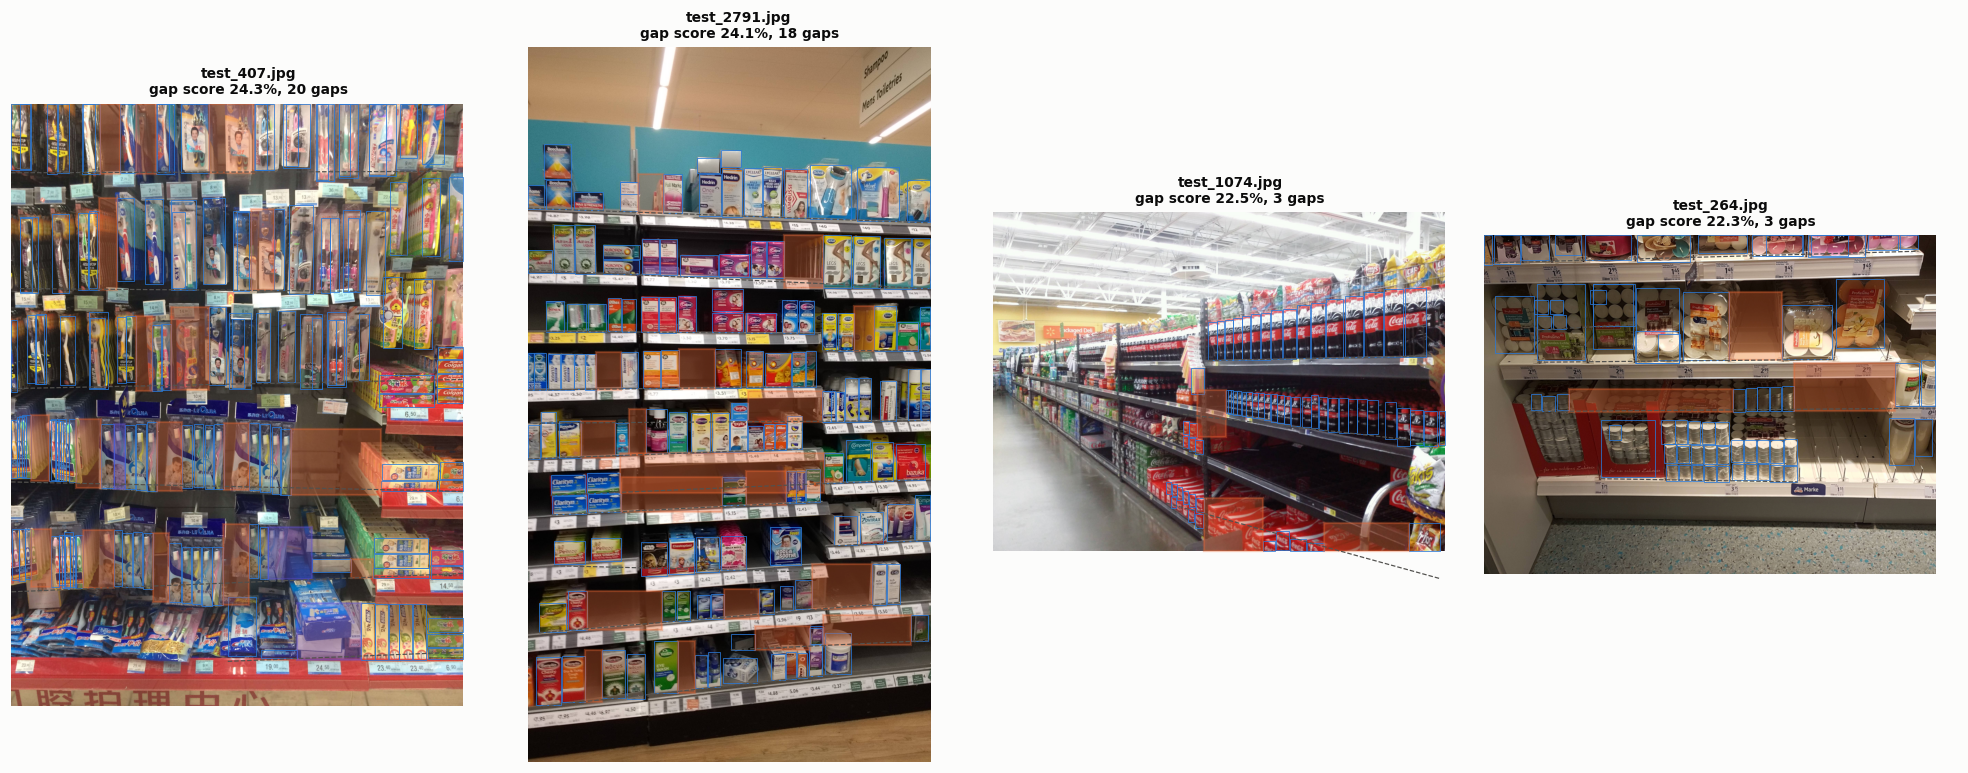

In [10]:
score_df["miss_share"] = score_df.n_missed_product_gaps / score_df.n_gaps.clip(lower=1)
top = score_df.nlargest(30, "gap_score")
rest = score_df.drop(top.index)
print(score_df.gap_score.describe().round(3))
print(f"Top 10% of images hold {top.n_gaps.sum() / score_df.n_gaps.sum():.0%} of all gaps")
print(f"Detector-miss share of gaps: top 10% {top.n_missed_product_gaps.sum() / top.n_gaps.sum():.0%}"
      f" | rest {rest.n_missed_product_gaps.sum() / max(rest.n_gaps.sum(), 1):.0%}")
fig, axes = plt.subplots(1, 4, figsize=(18, 7))
for ax, name in zip(axes, top.image.head(8).tail(4)):
    draw_gaps(ax, name)
plt.tight_layout(); plt.show()

Then in the terminal, back up the results:
```bash
azcopy copy "$HOME/runs/day3" "https://stretail26561.blob.core.windows.net/retail-data/outputs/" --recursive
```

## Notes for LOG.md
- Precision and recall at conf 0.25 on the sample, and the size where recall starts to drop.
- Your failure types from A5.
- Gaps found, share empty in the labels too, and the `gap_factor` you'll take into Day 4.